# Introduction
  
The fraud prevention department of a financial institute has a stablished process to classify suspicious transactions. The growing volume of transactions made the manual process inefficient and hard do scale, creating a twofold challenge: the risk of financial losses due to fraud that goes undetected in a timely manner, and the negative impact on the customer experience when legitimate transactions are incorrectly blocked.  
To improve efficiency and accuracy, the institution aims to develop a Machine Learning solution to automate the identification of fraudulent transactions.  
For the model creation it is provided a dataset with historical transaction records, already classified as fraudulent or no fraudulent.

# Exploratory Data Analysis

In [543]:
# for data manipulation
import pandas as pd
import numpy as np

# for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Separating dataset
from sklearn.model_selection import train_test_split

#transforming variable data into numerical data
from sklearn.preprocessing import OneHotEncoder, TargetEncoder

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
)
from lightgbm import LGBMClassifier


In [544]:
df = pd.read_csv("../data/raw/transacoes_historico_2025.csv")

df_jan2026 = pd.read_csv("../data/raw/transacoes_jan2026.csv")

# looking at the dataset structure (columns and values)
df.head()

,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,flag_fraude,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao
0,2025-01-01 00:00:00,Pharmacy Z,Pharmacy,9.12,Cliente_16621,Recife,False,desktop,False,31.5,72519-282,562,madrugada,baixo,Nordeste
1,2025-01-01 00:01:00,Supermarket A,Supermarket,37.74,Cliente_12596,Recife,False,mobile,False,28.1,43549-179,461,madrugada,medio,Nordeste
2,2025-01-01 00:02:00,Restaurant Y,Food & Beverage,30.94,Cliente_10474,Salvador,False,mobile,True,29.1,68582-277,577,madrugada,medio,Nordeste
3,2025-01-01 00:03:00,Gas Station,Fuel,41.72,Cliente_20661,Salvador,False,mobile,True,28.6,21497-208,666,madrugada,medio,Nordeste
4,2025-01-01 00:04:00,Online Shop 2,E-commerce,13.85,Cliente_4018,Rio de Janeiro,False,mobile,False,30.2,50814-648,892,madrugada,baixo,Sudeste


In [545]:
df.columns

Index(['datahora_transacao', 'nome_estabelecimento', 'tipo_estabelecimento', 'valor_transacao', 'nome_cliente', 'cidade', 'flag_fraude', 'device_type', 'is_new_device', 'temperatura_celsius', 'codigo_postal', 'score_interno', 'turno', 'valor_categoria', 'cidade_regiao'], dtype='str')

In [546]:
# dataframe dimensions
df.shape

print(df.shape[0], "data entries in", df.shape[1], 'columns')
print('Duplicated values:', df.duplicated().sum())
print('\nColumns info:')
df.info()

523525 data entries in 15 columns
Duplicated values: 0

Columns info:
<class 'pandas.DataFrame'>
RangeIndex: 523525 entries, 0 to 523524
Data columns (total 15 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   datahora_transacao    523525 non-null  str    
 1   nome_estabelecimento  523525 non-null  str    
 2   tipo_estabelecimento  523525 non-null  str    
 3   valor_transacao       523525 non-null  float64
 4   nome_cliente          523525 non-null  str    
 5   cidade                523525 non-null  str    
 6   flag_fraude           523525 non-null  bool   
 7   device_type           523525 non-null  str    
 8   is_new_device         523525 non-null  bool   
 9   temperatura_celsius   523525 non-null  float64
 10  codigo_postal         523525 non-null  str    
 11  score_interno         523525 non-null  int64  
 12  turno                 523525 non-null  str    
 13  valor_categoria       523525 non-null  str   

In [547]:
# checking the number of unique values in each column
columns = ['datahora_transacao',
           'nome_estabelecimento',
           'tipo_estabelecimento',
           'valor_transacao',
           'nome_cliente',
           'cidade',
           'flag_fraude',
           'device_type',
           'is_new_device',
           'temperatura_celsius',
           'codigo_postal',
           'score_interno',
           'turno',
           'valor_categoria',
           'cidade_regiao'
        ]

for col in columns:
  print(f'{col}:', df[col].nunique())

datahora_transacao: 523525
nome_estabelecimento: 10
tipo_estabelecimento: 6
valor_transacao: 29246
nome_cliente: 26214
cidade: 7
flag_fraude: 2
device_type: 3
is_new_device: 2
temperatura_celsius: 533
codigo_postal: 521905
score_interno: 1001
turno: 4
valor_categoria: 3
cidade_regiao: 3


In [548]:
# checking the unique values of 'cidade_regiao'
df['cidade_regiao'].unique()

<StringArray>
['Nordeste', 'Sudeste', 'Sul']
Length: 3, dtype: str

## Dataset Overview

- The original dataset has 523525 data entries and 15 columns;
- No null values were detected in the dataset;  
- No duplicated values were detected;
  
Decisions after dataset overview:
- Transform 'datahora_transacao' type from 'str' into 'datetime' type
- Transform 'tipo_estabelecimento', 'device_type', 'turno', 'valor_categoria' into 'category' type
- Transform 'cidade_regiao' in 'category' type and add the regions that are not on the list

In [549]:
# converting datahora_transacao column type from str to datetime

df['datahora_transacao'] = pd.to_datetime(df['datahora_transacao'])

# converting str columns to category
columns = [
    'tipo_estabelecimento',
    'device_type',
    'turno',
    'valor_categoria'
]

for col in columns:
  df[col] = df[col].astype('category')

In [550]:
# creating a list of the regions
regions = ['Norte', 'Nordeste', 'Centro-Oeste', 'Sudeste', 'Sul']

# transforming the type of the column with the list of regions
df['cidade_regiao'] = pd.Categorical(
    df['cidade_regiao'], categories=regions, ordered=False
)


df.info()

<class 'pandas.DataFrame'>
RangeIndex: 523525 entries, 0 to 523524
Data columns (total 15 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   datahora_transacao    523525 non-null  datetime64[us]
 1   nome_estabelecimento  523525 non-null  str           
 2   tipo_estabelecimento  523525 non-null  category      
 3   valor_transacao       523525 non-null  float64       
 4   nome_cliente          523525 non-null  str           
 5   cidade                523525 non-null  str           
 6   flag_fraude           523525 non-null  bool          
 7   device_type           523525 non-null  category      
 8   is_new_device         523525 non-null  bool          
 9   temperatura_celsius   523525 non-null  float64       
 10  codigo_postal         523525 non-null  str           
 11  score_interno         523525 non-null  int64         
 12  turno                 523525 non-null  category      
 13  valor_cate

# Transactions and Fraud Analysis

Before transactions and fraud analysis it was created a new column to the dataset to add binary values to fraudulent transactions.

In [551]:
# adding binary values to fraud transactions

df['fraude'] = (df['flag_fraude'] == True).astype(int)
df.head(2)

,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,flag_fraude,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao,fraude
0,2025-01-01 00:00:00,Pharmacy Z,Pharmacy,9.12,Cliente_16621,Recife,False,desktop,False,31.5,72519-282,562,madrugada,baixo,Nordeste,0
1,2025-01-01 00:01:00,Supermarket A,Supermarket,37.74,Cliente_12596,Recife,False,mobile,False,28.1,43549-179,461,madrugada,medio,Nordeste,0


In [552]:
# count of frauds and percentage
df_fraud = df['fraude'].value_counts().sort_index().to_frame('Quantity')
df_fraud['percentage'] = df['fraude'].value_counts(normalize=True).sort_index() *100
df_fraud

,Quantity,percentage
fraude,,
0,503040,96.087102
1,20485,3.912898


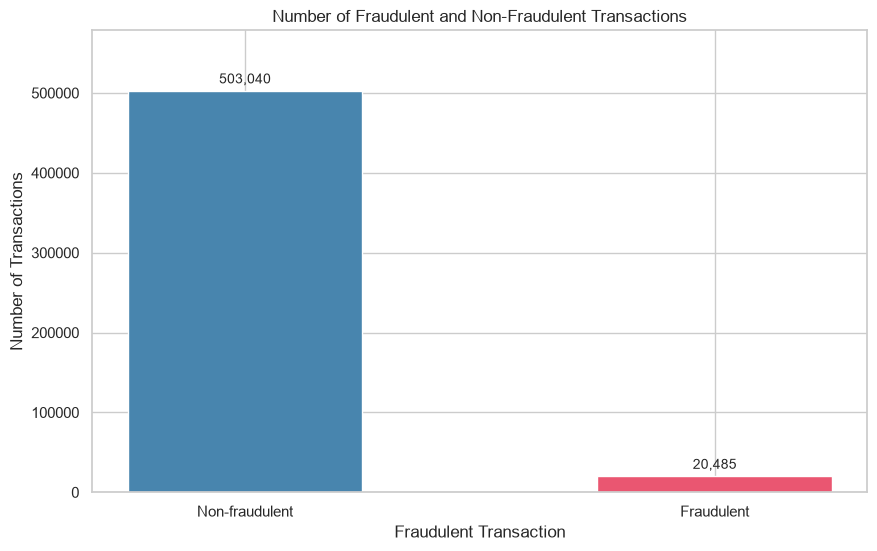

In [553]:
# Bar graph of the number of fraudulent and non fraudulent transactions
colors = ["#4885AE", "#EA5671"]
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.bar(
    ['Non-fraudulent', 'Fraudulent'],
    df_fraud['Quantity'],
    color=colors,
    width=0.5
)
ax.bar_label(barras, fmt='{:,.0f}', padding=3, fontsize=10)

ax.set_ylim(0, df_fraud['Quantity'].max() * 1.15)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Non-fraudulent', 'Fraudulent'])
plt.xlabel('Fraudulent Transaction')
plt.ylabel('Number of Transactions')
plt.title('Number of Fraudulent and Non-Fraudulent Transactions')
plt.show()

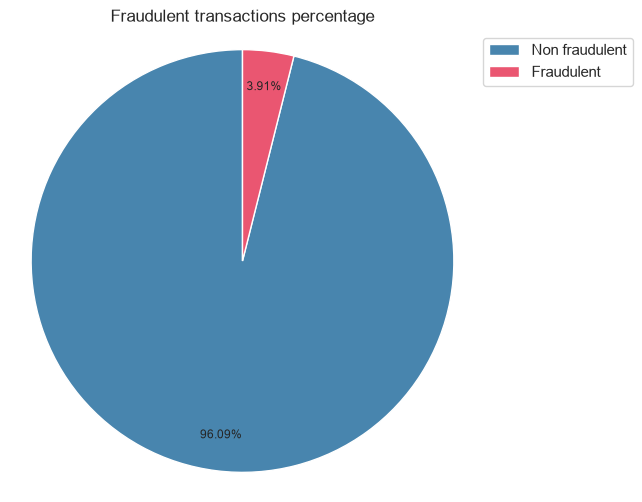

In [554]:
# Pie chart of the percentage of fraudulent and non fraudulent transactions

labels = ['Non fraudulent', 'Fraudulent']
colors = ["#4885AE", "#EA5671"]

figura, grafico = plt.subplots(figsize=(6, 6))

grafico.pie(df_fraud['percentage'], autopct='%1.2f%%', colors=colors, startangle = 90, textprops= {'fontsize': 8.5}, pctdistance=0.83)

grafico.axis('equal')
plt.title('Fraudulent transactions percentage')
plt.legend(labels, loc='upper left', bbox_to_anchor = (1, 1))

plt.show()

In [ ]:
total_geral = len(df)

# calculating the number and percentage of frauds per stablishments
fraud_per_stablishment_type = (
    df.groupby('tipo_estabelecimento')['fraude']
    .agg(
        total_transactions='count',  # total transactions
        total_frauds='sum',  # Sum of 1s
        taxa_fraud_pct=lambda x: (x.sum() / x.count())
        * 100,  # pct calc
    )
    .reset_index()
)


fraud_per_stablishment_type['trans_pct'] = (
    fraud_per_stablishment_type['total_transactions'] / total_geral
) * 100


fraud_per_stablishment_type = fraud_per_stablishment_type[
    [
        'tipo_estabelecimento',
        'total_transactions',
        'trans_pct',
        'total_frauds',
        'taxa_fraud_pct',
    ]
]


fraud_per_stablishment_type = fraud_per_stablishment_type.sort_values(by='taxa_fraud_pct', ascending=False)

pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', None)

print(fraud_per_stablishment_type)

  tipo_estabelecimento  total_transactions  trans_pct  total_frauds  taxa_fraud_pct
2                 Fuel               52163   9.963803          3937        7.547495
1      Food & Beverage              104675  19.994270          6939        6.629090
0           E-commerce              105223  20.098945          3288        3.124792
4               Retail              104648  19.989112          2623        2.506498
5          Supermarket              104225  19.908314          2475        2.374670
3             Pharmacy               52591  10.045557          1223        2.325493


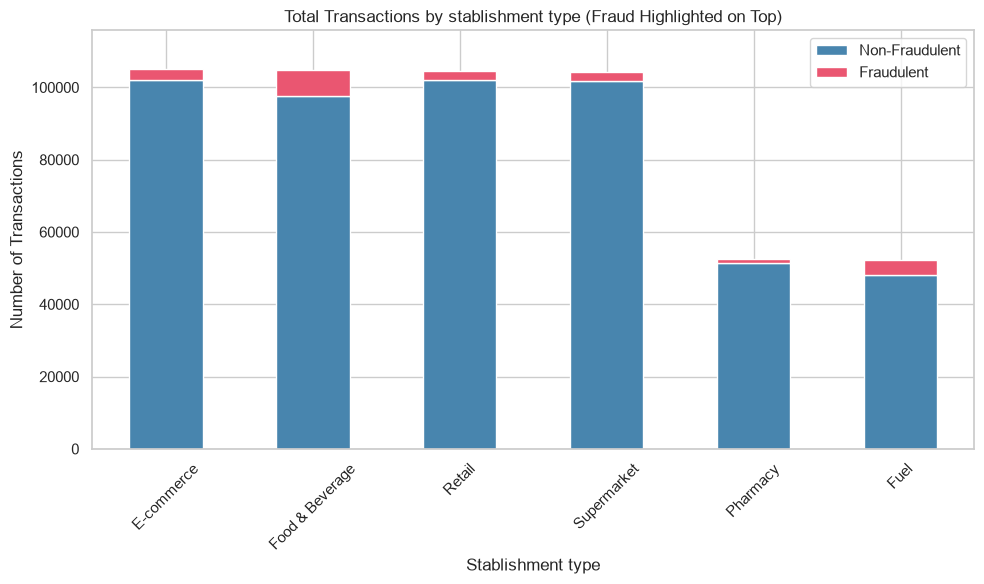

In [556]:
# 1. Agrupa os dados calculando o total de transações e a quantidade de fraudes
fraud_per_stablishment_type = (
    df.groupby('tipo_estabelecimento')['fraude']
    .agg(
        total_transactions='count',  # Total de linhas
        total_frauds='sum'           # Soma dos 1s (fraudes)
    )
    .reset_index()
)

# Cria a coluna com as transações normais (não fraudulentas) para o empilhamento
fraud_per_stablishment_type['non_frauds'] = (
    fraud_per_stablishment_type['total_transactions'] - fraud_per_stablishment_type['total_frauds']
)

# Calcula a porcentagem correta (multiplicando por 100) caso queira usar depois
fraud_per_stablishment_type['taxa_fraud_pct'] = (
    fraud_per_stablishment_type['total_frauds'] / fraud_per_stablishment_type['total_transactions']
) * 100

# Ordena do maior para o menor volume total de transações
fraud_per_stablishment_type = fraud_per_stablishment_type.sort_values(by='total_transactions', ascending=False)

# Define o 'stablishment_type' como índice para facilitar a plotagem empilhada do Pandas
fraud_per_stablishment_type = fraud_per_stablishment_type.set_index('tipo_estabelecimento')

# 2. Plota o Gráfico de Barras Empilhadas
fig, ax = plt.subplots(figsize=(10, 6))

# Definimos as cores: Azul para transações normais e Vermelho/Rosa para destacar as fraudes na ponta
colors = ['#4885AE', '#EA5671']

# Selecionamos apenas as colunas que compõem o empilhamento ('non_frauds' fica embaixo, 'total_frauds' fica em cima)
fraud_per_stablishment_type[['non_frauds', 'total_frauds']].plot(
    kind='bar',
    stacked=True,
    color=colors,
    figsize=(10, 6),
    ax=ax
)

# Ajusta um respiro no limite superior do eixo Y para o número não ser cortado
ax.set_ylim(0, totals.max() * 1.10)

# Ajustes de rótulos, títulos e legenda
plt.xlabel('Stablishment type')
plt.ylabel('Number of Transactions')
plt.title('Total Transactions by stablishment type (Fraud Highlighted on Top)')
plt.xticks(rotation=45)  # Mantém os nomes dos dispositivos retos

# Modifica a legenda para ficar mais amigável
plt.legend(['Non-Fraudulent', 'Fraudulent'], loc='upper right')

plt.tight_layout()
plt.show()

In [ ]:
total_geral = len(df)

# calculating the number and percentage of frauds per region
fraud_per_region = (
    df.groupby('cidade_regiao')['fraude']
    .agg(
        total_transactions='count',
        total_frauds='sum',
        taxa_fraud_pct=lambda x: (x.sum() / x.count())
        * 100,
    )
    .reset_index()
)

fraud_per_region['trans_pct'] = (
    fraud_per_region['total_transactions'] / total_geral
) * 100


fraud_per_region = fraud_per_region[
    [
        'cidade_regiao',
        'total_transactions',
        'trans_pct',
        'total_frauds',
        'taxa_fraud_pct',
    ]
]

fraud_per_region = fraud_per_region.sort_values(by='taxa_fraud_pct', ascending=False)

print(fraud_per_region)

  cidade_regiao  total_transactions  trans_pct  total_frauds  taxa_fraud_pct
1       Sudeste              224124  42.810563         11038        4.924952
2           Sul              149976  28.647343          5578        3.719262
0      Nordeste              149425  28.542094          3869        2.589259


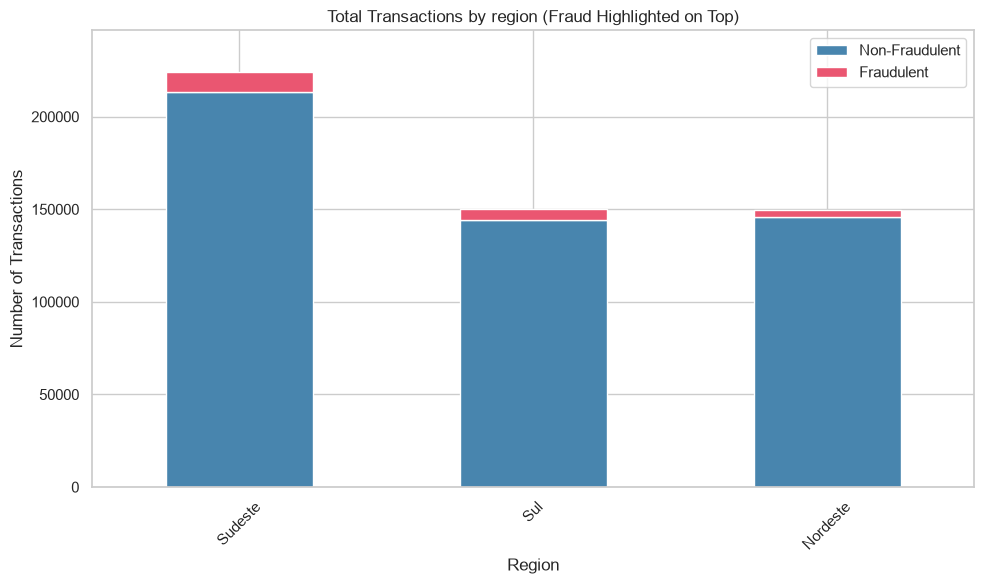

In [575]:
fraud_per_region = (
    df.groupby('cidade_regiao')['fraude']
    .agg(
        total_transactions='count',
        total_frauds='sum'
    )
    .reset_index()
)

# creating column of non fraudulent transactions
fraud_per_region['non_frauds'] = (
    fraud_per_region['total_transactions'] - fraud_per_region['total_frauds']
)

# # Calcula a porcentagem correta (multiplicando por 100) caso queira usar depois
# fraud_per_region['taxa_fraud_pct'] = (
#     fraud_per_region['total_frauds'] / fraud_per_region['total_transactions']
# ) * 100


fraud_per_region = fraud_per_region.sort_values(by='total_transactions', ascending=False)


fraud_per_region = fraud_per_region.set_index('cidade_regiao')


fig, ax = plt.subplots(figsize=(10, 6))


colors = ['#4885AE', '#EA5671']

fraud_per_region[['non_frauds', 'total_frauds']].plot(
    kind='bar',
    stacked=True,
    color=colors,
    figsize=(10, 6),
    ax=ax
)


ax.set_ylim(0, fraud_per_region['total_transactions'].max() * 1.10)

plt.xlabel('Region')
plt.ylabel('Number of Transactions')
plt.title('Total Transactions by region (Fraud Highlighted on Top)')
plt.xticks(rotation=45)
plt.legend(['Non-Fraudulent', 'Fraudulent'], loc='upper right')

plt.tight_layout()
plt.show()

In [576]:
total_geral = len(df)

# calculating the number and percentage of frauds per category value
fraud_per_category_value = (
    df.groupby('valor_categoria')['fraude']
    .agg(
        total_transactions='count',  # Conta o total de linhas (transações)
        total_frauds='sum',  # Soma os 1s (quantidade de fraudes)
        taxa_fraud_pct=lambda x: (x.sum() / x.count())
        * 100,  # Calcula a % de fraude
    )
    .reset_index()
)

fraud_per_category_value['trans_pct'] = (
    fraud_per_category_value['total_transactions'] / total_geral
) * 100

fraud_per_category_value = fraud_per_category_value[
    [
        'valor_categoria',
        'total_transactions',
        'trans_pct',
        'total_frauds',
        'taxa_fraud_pct',
    ]
]


fraud_per_category_value = fraud_per_category_value.sort_values(by='taxa_fraud_pct', ascending=False)

print(fraud_per_category_value)

  valor_categoria  total_transactions  trans_pct  total_frauds  taxa_fraud_pct
2           medio              185148  35.365646          8563        4.624949
1           baixo              304015  58.070770         11825        3.889611
0            alto               34362   6.563583            97        0.282289


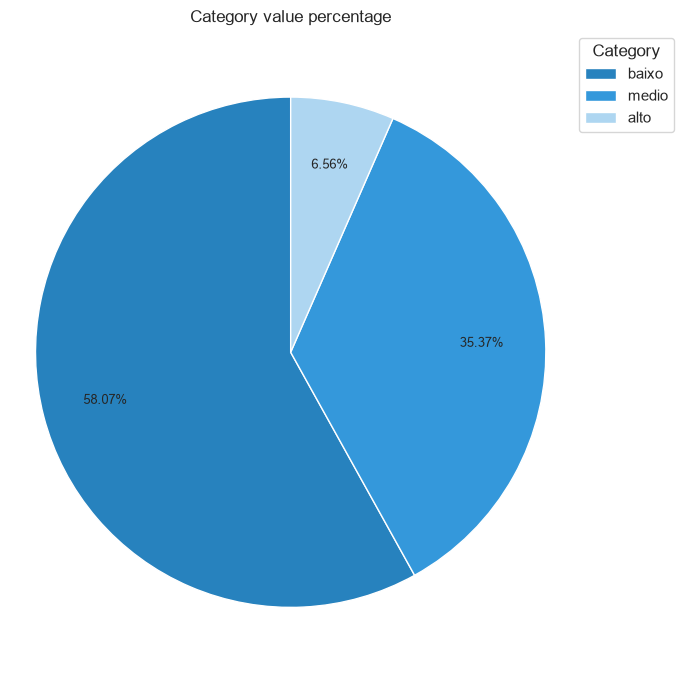

In [588]:
# pie chart of category values percentage
df_category_value = (
    df['valor_categoria'].value_counts().sort_values(ascending=False)
)

colors = ["#2782BE", '#3498DB', '#AED6F1']

figura, grafico = plt.subplots(figsize=(7, 7))

grafico.pie(
    df_category_value,
    autopct='%1.2f%%',
    startangle=90,
    colors=colors[: len(df_category_value)],
    textprops={'fontsize': 9},
    pctdistance=0.75,
)

grafico.axis('equal')

plt.title('Category value percentage')
plt.legend(
    df_category_value.index,
    title='Category',
    loc='upper left',
    bbox_to_anchor=(1, 1),
)

plt.tight_layout()
plt.show()

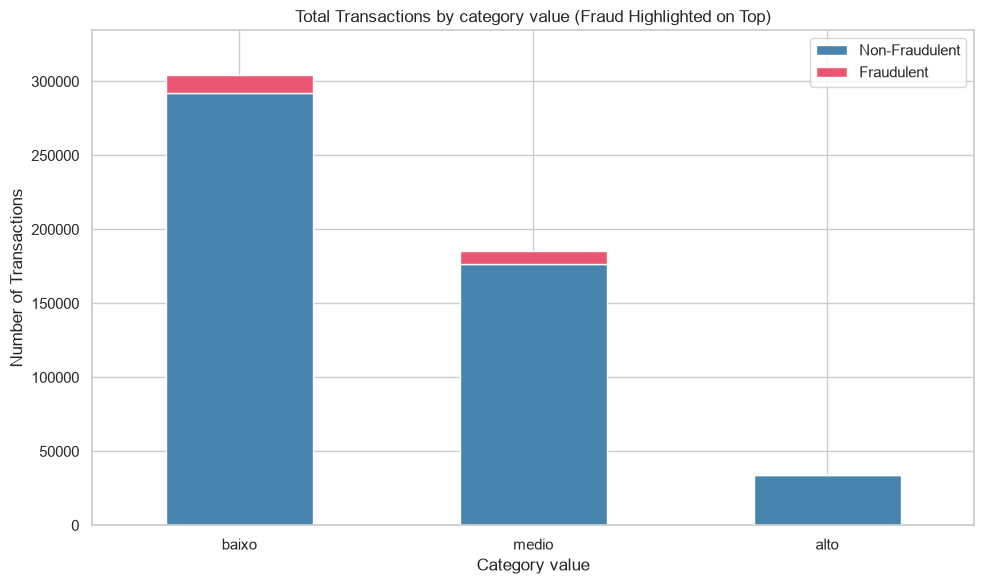

In [561]:
# Agg total transactions + frauds
fraud_per_category_value = (
    df.groupby('valor_categoria')['fraude']
    .agg(
        total_transactions='count',  # Total de linhas
        total_frauds='sum'           # Soma dos 1s (fraudes)
    )
    .reset_index()
)

# creating column with normal transactions
fraud_per_category_value['non_frauds'] = (
    fraud_per_category_value['total_transactions'] - fraud_per_category_value['total_frauds']
)

# Calculating pct of frauds
fraud_per_category_value['taxa_fraud_pct'] = (
    fraud_per_category_value['total_frauds'] / fraud_per_category_value['total_transactions']
) * 100

# sorting transactions
fraud_per_category_value = fraud_per_category_value.sort_values(by='total_transactions', ascending=False)

fraud_per_category_value = fraud_per_category_value.set_index('valor_categoria')

# Plotting the bar graph
fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#4885AE', '#EA5671']

# Selecting columns for the bars
fraud_per_category_value[['non_frauds', 'total_frauds']].plot(
    kind='bar',
    stacked=True,
    color=colors,
    figsize=(10, 6),
    ax=ax
)


ax.set_ylim(0, fraud_per_category_value['total_transactions'].max() * 1.10)
plt.xlabel('Category value')
plt.ylabel('Number of Transactions')
plt.title('Total Transactions by category value (Fraud Highlighted on Top)')
plt.xticks(rotation=0)  # Mantém os nomes dos dispositivos retos
plt.legend(['Non-Fraudulent', 'Fraudulent'], loc='upper right')

plt.tight_layout()
plt.show()

In [577]:
total_geral = len(df)

# calculating the number and percentage of frauds per category value
fraud_per_device_type = (
    df.groupby('device_type')['fraude']
    .agg(
        total_transactions='count',  # Conta o total de linhas (transações)
        total_frauds='sum',  # Soma os 1s (quantidade de fraudes)
        taxa_fraud_pct=lambda x: (x.sum() / x.count())
        * 100,  # Calcula a % de fraude
    )
    .reset_index()
)

fraud_per_device_type['trans_pct'] = (
    fraud_per_device_type['total_transactions'] / total_geral
) * 100


fraud_per_device_type = fraud_per_device_type[
    [
        'device_type',
        'total_transactions',
        'trans_pct',
        'total_frauds',
        'taxa_fraud_pct',
    ]
]

# Ordena da maior taxa de fraude para a menor
fraud_per_device_type = fraud_per_device_type.sort_values(by='taxa_fraud_pct', ascending=False)

print(fraud_per_device_type)

  device_type  total_transactions  trans_pct  total_frauds  taxa_fraud_pct
1      mobile              291056  55.595435         14306        4.915205
0     desktop              181262  34.623370          5123        2.826296
2      tablet               51207   9.781195          1056        2.062218


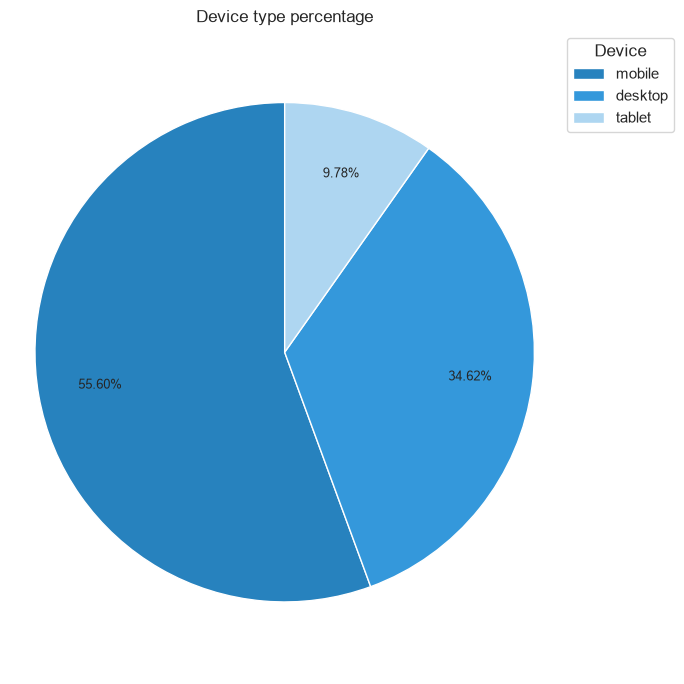

In [563]:
df_device = (
    df['device_type'].value_counts().sort_values(ascending=False)
)

colors = ["#2782BE", '#3498DB', '#AED6F1']

figura, grafico = plt.subplots(figsize=(7, 7))

grafico.pie(
    df_device,
    autopct='%1.2f%%',
    startangle=90,
    colors=colors[: len(df_device)],
    textprops={'fontsize': 9},
    pctdistance=0.75,
)

grafico.axis('equal')

plt.title('Device type percentage')
plt.legend(
    df_device.index,
    title='Device',
    loc='upper left',
    bbox_to_anchor=(1, 1),
)

plt.tight_layout()
plt.show()

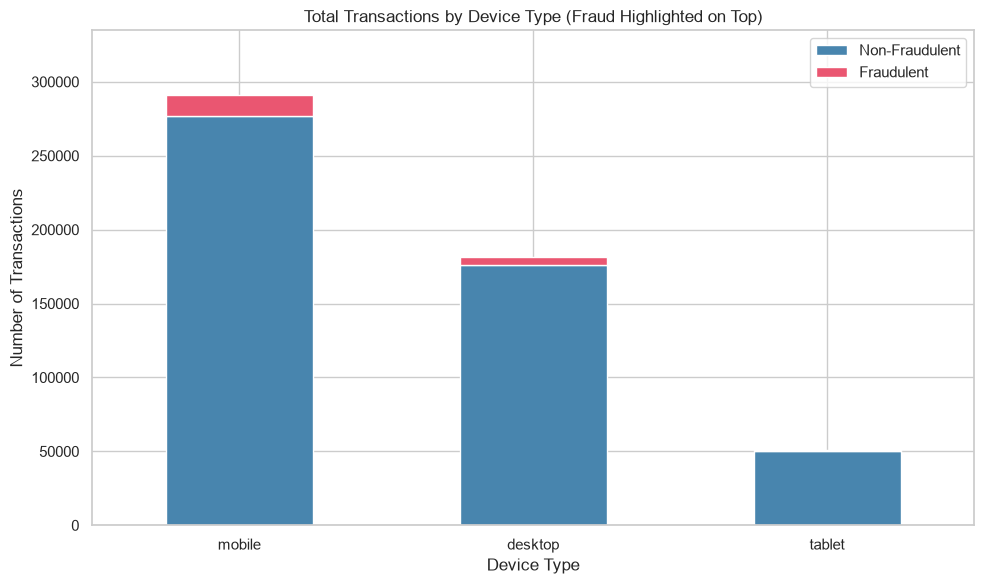

In [ ]:
fraud_per_device_type = (
    df.groupby('device_type')['fraude']
    .agg(
        total_transactions='count',  # Total de linhas
        total_frauds='sum',  # Soma dos 1s (fraudes)
    )
    .reset_index()
)

fraud_per_device_type['non_frauds'] = (
    fraud_per_device_type['total_transactions']
    - fraud_per_device_type['total_frauds']
)


fraud_per_device_type['taxa_fraud_pct'] = (
    fraud_per_device_type['total_frauds']
    / fraud_per_device_type['total_transactions']
) * 100


fraud_per_device_type = fraud_per_device_type.sort_values(
    by='total_transactions', ascending=False
)


fraud_per_device_type_plot = fraud_per_device_type.set_index('device_type')


fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#4885AE', '#EA5671']

fraud_per_device_type_plot[['non_frauds', 'total_frauds']].plot(
    kind='bar', stacked=True, color=colors, ax=ax
)


ax.set_ylim(0, fraud_per_device_type['total_transactions'].max() * 1.15)
plt.xlabel('Device Type')
plt.ylabel('Number of Transactions')
plt.title('Total Transactions by Device Type (Fraud Highlighted on Top)')
plt.xticks(rotation=0)
plt.legend(['Non-Fraudulent', 'Fraudulent'], loc='upper right')

plt.tight_layout()
plt.show()

In [ ]:
total_geral = len(df)

fraud_per_shift = (
    df.groupby('turno')['fraude']
    .agg(
        total_transactions='count',
        total_frauds='sum',
        taxa_fraud_pct=lambda x: (x.sum() / x.count())
        * 100,
    )
    .reset_index()
)

fraud_per_shift['trans_pct'] = (
    fraud_per_shift['total_transactions'] / total_geral
) * 100

fraud_per_shift = fraud_per_shift[
    [
        'turno',
        'total_transactions',
        'trans_pct',
        'total_frauds',
        'taxa_fraud_pct',
    ]
]

fraud_per_shift = fraud_per_shift.sort_values(by='taxa_fraud_pct', ascending=False)

print(fraud_per_shift)

       turno  total_transactions  trans_pct  total_frauds  taxa_fraud_pct
2      noite              130876  24.998997         13403       10.240991
3      tarde              130871  24.998042          4449        3.399531
0  madrugada              130850  24.994031          1764        1.348109
1      manha              130928  25.008930           869        0.663724


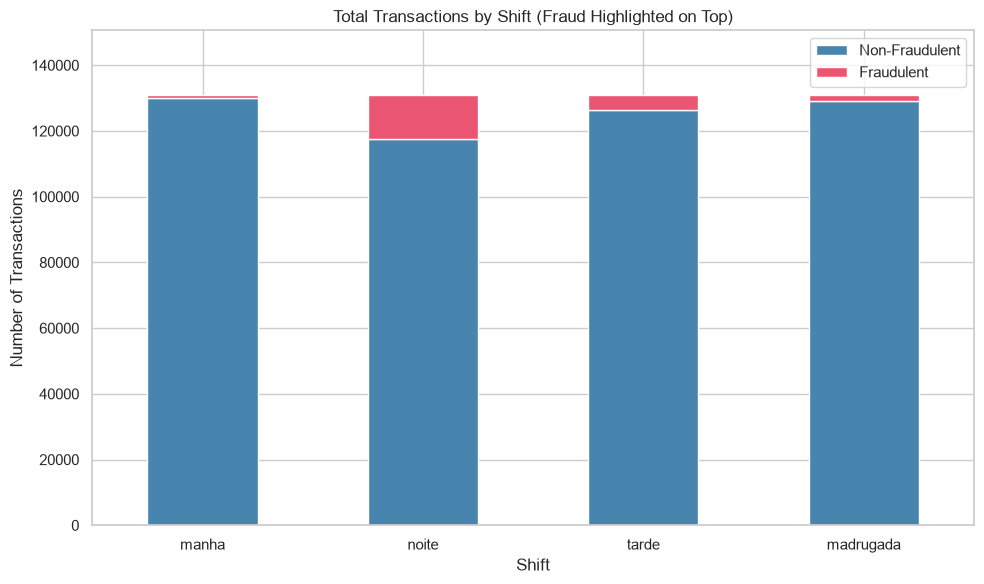

In [ ]:
fraud_per_shift = (
    df.groupby('turno')['fraude']
    .agg(
        total_transactions='count',
        total_frauds='sum',
    )
    .reset_index()
)


fraud_per_shift['non_frauds'] = (
    fraud_per_shift['total_transactions'] - fraud_per_shift['total_frauds']
)

fraud_per_shift['taxa_fraud_pct'] = (
    fraud_per_shift['total_frauds'] / fraud_per_shift['total_transactions']
) * 100


fraud_per_shift = fraud_per_shift.sort_values(
    by='total_transactions', ascending=False
)


fraud_per_shift_plot = fraud_per_shift.set_index('turno')

fig, ax = plt.subplots(figsize=(10, 6))


colors = ['#4885AE', '#EA5671']


fraud_per_shift_plot[['non_frauds', 'total_frauds']].plot(
    kind='bar', stacked=True, color=colors, ax=ax
)
ax.set_ylim(0, fraud_per_shift['total_transactions'].max() * 1.15)
plt.xlabel('Shift')
plt.ylabel('Number of Transactions')
plt.title('Total Transactions by Shift (Fraud Highlighted on Top)')
plt.xticks(rotation=0)
plt.legend(['Non-Fraudulent', 'Fraudulent'], loc='upper right')

plt.tight_layout()
plt.show()

- Less than 4% of the transactions were classified as fraudulent (20485 total);
- 96% of the transactions were classified as non fraudulent;  
  
  
- The stablishments' transactions were analyzed and it was observed that the 'e-commerce' had the most transactions among all stablishments and 'fuel' and 'pharmacy' had the least;
- 'Fuel' and 'pharmacy' together represented less than 20% of the transactions, while the other stablishments had percentage of about 20%;
- The stablishment type that presented the highest percentage of fraudulent transactions was fuel, which had 7% of fraudulent transactions in 52163;  
  

- There was no transaction counted for regions 'centro-oeste' and 'norte';
- 'sudeste' region had more than 224.000 transactions, while 'sul' and 'nordeste' had aproximately 150.000 each;
- Region 'Sudeste' had most fraudulent transactions among all regions, which is expected when looking at the number of transactions, this region presented 75.000 more transactions than the other two regions ('Sul' and 'Nordeste'), that had about 149.000 transactions each;
  

- There were no difference among the number of transactions when comparing the shifts. However, the amount of frauds at night is a lot higher than the other shifts;
  

- The amount of transactions of low category counted more than 300.000 transactions, while the 'alta' category had less than 35.000 transactions;
- Low category transaction ('baixo') had the most amount of transactions among all categories (304015 transactions, respectively), representing more than 58% of transactions, but medium category ('medio') had the most fraudulent percentage (4,62% in 304015 transations); 
   

- The mobile transactions had about 110.000 more transactions than desktop transactions, which had 181,262. Mobile transactions represented more than 55%, while tablet transactions represented only about 10%;  
- 




# Correlation Matrix

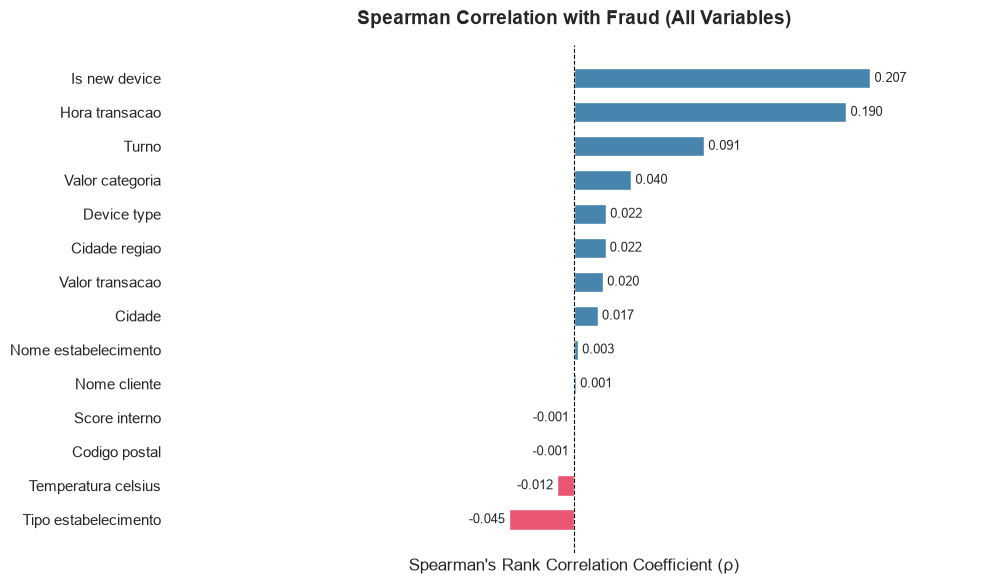

In [579]:
df_corr = df.copy()


# Automatically convert ALL non-numeric columns into numeric codes
for col in df_corr.select_dtypes(
    include=['object', 'category', 'string', 'bool']
).columns:
  if col != 'fraude':
    df_corr[col] = df_corr[col].astype('category').cat.codes

# If there is a datetime column, we can extract the hour to include in the correlation
if 'datahora_transacao' in df_corr.columns:
  df_corr['hora_transacao'] = pd.to_datetime(
      df_corr['datahora_transacao']
  ).dt.hour
  df_corr = df_corr.drop(columns=['datahora_transacao'])

# Calculate the Spearman correlation of ALL columns with respect to 'fraude'
# drop 'fraude' itself so it doesn't appear in the plot with a 1.0 correlation
correlacao = (
    df_corr.corr(method='spearman')['fraude']
    .drop(['flag_fraude', 'fraude'])
    .sort_values()
)

# Standardize index names to look clean on the chart
correlacao.index = correlacao.index.str.replace('_', ' ').str.capitalize()

# Define conditional colors (Blue for positive/increases fraud, Red for negative/protects)
cores = np.where(correlacao > 0, '#4885AE', '#EA5671')

# Plot the horizontal bar chart adjusted to the number of columns
plt.figure(figsize=(10, max(6, len(correlacao) * 0.4)))
barras = plt.barh(correlacao.index, correlacao.values, color=cores, height=0.6)

# Add exact values on the tips of the bars
plt.bar_label(barras, fmt='%.3f', padding=3, fontsize=9)

# Reference line at zero
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')

# Titles and labels
plt.title(
    'Spearman Correlation with Fraud (All Variables)',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
plt.xlabel("Spearman's Rank Correlation Coefficient (ρ)")

# Dynamic limits so numbers don't get cut off at the edges
max_val = max(abs(correlacao.min()), abs(correlacao.max()))
plt.xlim(-max_val * 1.35, max_val * 1.35)
plt.xticks([])
plt.grid(False)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

- Before the matrix correlation analysis, the columns that didn't have numerical values were transformed temporarily into numerical values for the analysis;  
- The matrix correlation method applied was the Spearman method, which evaluate the monotonic association of the variable (the variable tend to increase or decrease as the other increases);  
- The method was chosen because the dataset of financial data usually have extreme values and assimetry, that can distort correlations when using the Pearson method;  
- The matrix analyzed the correlation between each column with the variable 'fraude', which has binary values;  
- The results were ploted in a horizontal bar graph that showed negative correlations in red and positive correlations in blue; 
   
Results:  
- All variables analyzed presented low correlation with 'fraude' column, indicating that those variables individually don't influence the 'fraude' variable. 

# Machine Learning model development, evaluation and inference

Before data transformation, the dataset was divided into training and test. It is done before transformation of data to avoid data leakage.

In [582]:
# Separating the dataset entries in train and test

y = df['flag_fraude'].astype(int) # target variable
X = df.drop(columns=['flag_fraude', 'fraude'])  # independent variables

#statified division
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) # stratify makes sure that fraud proportion is the same in test and train

print(f'Train - Lines: {X_train.shape[0]}, Fraudes: {y_train.sum()}')
print(f'Test  - Lines: {X_test.shape[0]}, Fraudes: {y_test.sum()}')

Train - Lines: 418820, Fraudes: 16388
Test  - Lines: 104705, Fraudes: 4097


# Data tranformation

After data division, non numerical data was transformed into numerical data using different approaches.  
The transformation method of the non numerical columns were based on the data type and cardinality.  
The methods chosen were:  
- One-hot encoding: 'turno', 'device_type', 'cidade_regiao', 'tipo_estabelecimento'
- Ordinal encoding: 'valor_categoria'
- Target encoding: 'nome_cliente', 'codigo_postal', 'nome_estabelecimento', 'cidade' 
- Transform boolean into binary values: 'is_new_device'
- For 'datahora_transacao': create 'dayofweek' and 'is_weekend' variables. 

The transformation used the training data to learn about the data before transforming them;    
The test set was transformed with the rules they learned from the training set.  

In [583]:
# Creating copies before applying any method
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()


# -------------------------------------------------------------
# 1. DATETIME PROCESSING
# -------------------------------------------------------------
def extract_datetime_features(df):
  # Ensure the column is datetime type
  dt = pd.to_datetime(df['datahora_transacao'])
  df['day_of_week'] = dt.dt.day_of_week
  df['is_weekend'] = (dt.dt.day_of_week >= 5).astype(int)
  # Drop the original datetime column
  df = df.drop(columns=['datahora_transacao'])
  return df


X_train_fe = extract_datetime_features(X_train_fe)
X_test_fe = extract_datetime_features(X_test_fe)


# -------------------------------------------------------------
# 2. BOOLEAN VARIABLE TO INTEGER CONVERSION
# -------------------------------------------------------------
X_train_fe['is_new_device'] = X_train_fe['is_new_device'].astype(int)
X_test_fe['is_new_device'] = X_test_fe['is_new_device'].astype(int)


# -------------------------------------------------------------
# 3. ORDINAL ENCODING ('valor_categoria')
# -------------------------------------------------------------
category_order = {'baixo': 0, 'medio': 1, 'alto': 2}
X_train_fe['valor_categoria'] = X_train_fe['valor_categoria'].map(
    category_order
)
X_test_fe['valor_categoria'] = X_test_fe['valor_categoria'].map(category_order)


# -------------------------------------------------------------
# 4. ONE-HOT ENCODING
# -------------------------------------------------------------
ohe_cols = ['turno', 'device_type', 'cidade_regiao', 'tipo_estabelecimento']

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fit and transform only on train, transform on test
train_ohe = ohe.fit_transform(X_train_fe[ohe_cols])
test_ohe = ohe.transform(X_test_fe[ohe_cols])

# Retrieve feature names generated by OHE
ohe_feature_names = ohe.get_feature_names_out(ohe_cols)

# Convert to DataFrames and concatenate back
train_ohe_df = pd.DataFrame(
    train_ohe, columns=ohe_feature_names, index=X_train_fe.index
)
test_ohe_df = pd.DataFrame(
    test_ohe, columns=ohe_feature_names, index=X_test_fe.index
)

X_train_fe = pd.concat(
    [X_train_fe.drop(columns=ohe_cols), train_ohe_df], axis=1
)
X_test_fe = pd.concat([X_test_fe.drop(columns=ohe_cols), test_ohe_df], axis=1)


# -------------------------------------------------------------
# 5. TARGET ENCODING (High Cardinality)
# -------------------------------------------------------------
target_cols = ['nome_cliente', 'codigo_postal', 'nome_estabelecimento', 'cidade']

# Note: Target Encoder requires the corresponding y_train to calculate fraud averages
te = TargetEncoder(smooth='auto', target_type='binary')

X_train_fe[target_cols] = te.fit_transform(X_train_fe[target_cols], y_train)
X_test_fe[target_cols] = te.transform(X_test_fe[target_cols])


# -------------------------------------------------------------
# 6. FINAL CLEANUP OF RESIDUAL COLUMNS
# -------------------------------------------------------------
# Remove legacy boolean flag_fraude if still present in features
if 'flag_fraude' in X_train_fe.columns:
  X_train_fe = X_train_fe.drop(columns=['flag_fraude'])
if 'flag_fraude' in X_test_fe.columns:
  X_test_fe = X_test_fe.drop(columns=['flag_fraude'])

print('Feature Engineering completed successfully!')
print(f'New dimensions of X_train_fe: {X_train_fe.shape}')
print(f'New dimensions of X_test_fe: {X_test_fe.shape}')

Feature Engineering completed successfully!
New dimensions of X_train_fe: (418820, 27)
New dimensions of X_test_fe: (104705, 27)


# Chosen Model
- The model chosen was LighGBM, which is widely used and showed good results in identifying fraudulent transactions.

In [585]:
print('--- Training LightGBM ---')

# Perfect alignment: ensures that X_test_fe has exacty the same columns and in the same order as X_train_fe
X_test_fe = X_test_fe.reindex(columns=X_train_fe.columns, fill_value=0)

# Remove any residual text/object/category columns that might have slipped through
non_numeric_cols = X_train_fe.select_dtypes(
    include=['object', 'category']
).columns.tolist()
if non_numeric_cols:
  print(f'Removing residual non-numeric columns: {non_numeric_cols}')
  X_train_fe = X_train_fe.drop(columns=non_numeric_cols, errors='ignore')
  X_test_fe = X_test_fe.drop(columns=non_numeric_cols, errors='ignore')

# Explicitly convert BOTH DataFrames to float (this removes any problematic 'category' dtypes)
X_train_fe = X_train_fe.astype(float)
X_test_fe = X_test_fe.astype(float)

lgb_model = LGBMClassifier(
    n_estimators=100,
    is_unbalance=True,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

lgb_model.fit(X_train_fe, y_train)

# Predictions
lgb_pred = lgb_model.predict(X_test_fe)
lgb_pred_proba = lgb_model.predict_proba(X_test_fe)[:, 1]


# -------------------------------------------------------------
# 2. EVALUATION FUNCTION & EXECUTION
# -------------------------------------------------------------
def evaluate_model(y_true, y_pred, y_pred_proba, model_name):
  print(f'\n================ {model_name} EVALUATION ================\n')
  print(f'Precision: {precision_score(y_true, y_pred):.4f}')
  print(f'Recall:    {recall_score(y_true, y_pred):.4f}')
  print(f'F1-Score:  {f1_score(y_true, y_pred):.4f}')
  print(f'ROC-AUC:   {roc_auc_score(y_true, y_pred_proba):.4f}')
  print('\nConfusion Matrix:')
  print(confusion_matrix(y_true, y_pred))
  print('\nClassification Report:')
  print(classification_report(y_true, y_pred))


# Evaluate LightGBM on the test set
evaluate_model(y_test, lgb_pred, lgb_pred_proba, 'LightGBM')

--- Training LightGBM ---

================ LightGBM EVALUATION ================

Precision: 0.1756
Recall:    0.9563
F1-Score:  0.2967
ROC-AUC:   0.9498

Confusion Matrix:
[[82209 18399]
 [  179  3918]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.82      0.90    100608
           1       0.18      0.96      0.30      4097

    accuracy                           0.82    104705
   macro avg       0.59      0.89      0.60    104705
weighted avg       0.97      0.82      0.87    104705



Recall and ROC-AUC results (95,63% and 0,9498, respectively) indicate that the model can separate legitimate transactions from fraudulent ones. However, looking at the Precision (17,56%), the low percentage indicates that the model misclassifies non-fraudulent transactions as fraudulent. The Precision pulls F1-Score down.  
  
The confusion matrix showed:  
- True Negatives (82,209): Normal transactions that the model correctly identified as normal.
- False Positives (18,399): Normal transactions that the model wrongly accused of being fraud (the cost here is a legitimate client having their purchase blocked or needing to go through extra verification).
- False Negatives (179): Real frauds that slipped past the model (the worst direct financial scenario).
- True Positives (3,918): Real frauds that the model successfully blocked.
  
Decisions:  
- Although Recall demonstrates excellent fraud-catching performance, the low precision of only 17% would incorrectly flag a large number of legitimate transactions. For that reason the threshold tuning is going to be applied, so the probability threshold is adjusted to achieve a better balance and improve precision.


# Improving model

In [586]:
# Get predicted probabilities for class 1 (fraud)
y_pred_proba = lgb_model.predict_proba(X_test_fe)[:, 1]

# Calculate precision, recall, and thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)

# Calculate the F1-Score for each possible threshold
# Avoid division by zero by adding a very small constant (1e-10)
f1_scores = (2 * (precisions * recalls)) / (precisions + recalls + 1e-10)

# Find the index that yields the highest F1-Score
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f'Best threshold found: {best_threshold:.4f}')
print(f'Expected Precision: {precisions[best_idx]:.4f}')
print(f'Expected Recall:    {recalls[best_idx]:.4f}')
print(f'Maximum F1-Score:   {f1_scores[best_idx]:.4f}')

# Apply the new threshold to the predictions
lgb_pred_optimized = (y_pred_proba >= best_threshold).astype(int)

# Evaluate with the optimized decision threshold
evaluate_model(y_test, lgb_pred_optimized, y_pred_proba, 'Optimized LightGBM')

Best threshold found: 0.8628
Expected Precision: 0.4056
Expected Recall:    0.5929
Maximum F1-Score:   0.4817

================ Optimized LightGBM EVALUATION ================

Precision: 0.4056
Recall:    0.5929
F1-Score:  0.4817
ROC-AUC:   0.9498

Confusion Matrix:
[[97048  3560]
 [ 1668  2429]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.96      0.97    100608
           1       0.41      0.59      0.48      4097

    accuracy                           0.95    104705
   macro avg       0.69      0.78      0.73    104705
weighted avg       0.96      0.95      0.95    104705



After applying threshold tuning, the new threshold of 0.8628 improved precision performance from 17% to 40%. It helped F1-Score improve from 0,29 to 0,48;  
The precision improvement made Recall result drop from 95% to 59,29%. This helps avoid legitimate transactions to be classified as fraudulent ones;  
  
Confusion Matrix:
- Before the threshold tuning, 18399 legitimate customers had their purchases blocked by mistake. After the threshold tuning, the number dropped to 3560;
- On the other hand, false negatives increased from 179 to 1668. 
  
These findings need to be discussed by the team to analyze if it is worth tolerating slightly more fraud to save thousands of honest customers.

# Inference on the January 2026 Dataset and Generation of the Final CSV

In [587]:
# 1. Load the blind dataset for January 2026
df_janeiro_2026 = pd.read_csv('../data/raw/transacoes_jan2026.csv')

# 2. Create a copy to preserve the original submission dataframe
df_submission = df_janeiro_2026.copy()
X_new = df_janeiro_2026.copy()

# 3. Apply the same date/time extraction function
X_new = extract_datetime_features(X_new)

# 4. Boolean to integer conversion
if 'is_new_device' in X_new.columns:
  X_new['is_new_device'] = X_new['is_new_device'].astype(int)

# 5. Ordinal Encoding ('valor_categoria')
if 'valor_categoria' in X_new.columns:
  X_new['valor_categoria'] = X_new['valor_categoria'].map(category_order)

# 6. One-Hot Encoding (only transform using the already trained 'ohe')
if ohe_cols:
  new_ohe = ohe.transform(X_new[ohe_cols])
  new_ohe_df = pd.DataFrame(
      new_ohe, columns=ohe.get_feature_names_out(ohe_cols), index=X_new.index
  )
  X_new = pd.concat([X_new.drop(columns=ohe_cols), new_ohe_df], axis=1)

# 7. Target Encoding (only transform using the already trained 'te')
if target_cols:
  X_new[target_cols] = te.transform(X_new[target_cols])

# 8. Clean up residual columns if they exist
if 'flag_fraude' in X_new.columns:
  X_new = X_new.drop(columns=['flag_fraude'])
if 'fraude' in X_new.columns:
  X_new = X_new.drop(columns=['fraude'])

# 9. Perfect column alignment with X_train_fe (ensures the same order and absence of discrepancies)
X_new = X_new.reindex(columns=X_train_fe.columns, fill_value=0)

# 10. Generate probabilities and apply the optimized threshold
final_pred_proba = lgb_model.predict_proba(X_new)[:, 1]
# Uses the 'best_threshold' variable generated in your Cell 4
final_predictions = (final_pred_proba >= best_threshold).astype(int)

# 11. Insert predictions into the original base and save the final file
df_submission['probabilidade_fraude'] = final_pred_proba
df_submission['fraude'] = (
    final_predictions  # Binary classification column
)

df_submission.to_csv('resultado_janeiro_2026.csv', index=False)

print("File 'resultado_janeiro_2026.csv' successfully generated!")
print(f'Total rows processed: {len(df_submission)}')
print(f'Total predicted frauds: {final_predictions.sum()}')

File 'resultado_janeiro_2026.csv' successfully generated!
Total rows processed: 44451
Total predicted frauds: 2535


# Conclusion and recommendations

The objective of this project was to develop a robust Machine Learning pipeline capable of identifying fraudulent transactions while minimizing unnecessary friction for legitimate customers.  
What was done in this project:  
- Exploratory Data Analysis (EDA), 
- Feature Engineering, 
- Model training via LightGBM, 
- Probability threshold tuning,
- Final production inference on the January 2026 dataset.
  
  
For production deployment on the January 2026 dataset (transacoes_jan2026.csv), the pipeline created was successfully applied and generated precise probability scores (probabilidade_fraude) and binary classification decisions (fraude) saved into the final submission file.  

Recommendation:  
Instead of forcing a binary choice between 'Fraudulent' and 'Non fraudulent' transactions at a single rigid threshold, it can be used a tiered strategy using the probability score (probabilidade_fraude):  
- Low Risk (< 0.50): Frictionless, legitimate transactions.
- Medium Risk (0.50 - 0.8628): Step-Up Authentication. Instead of outright blocking honest customers (false positives) or letting fraud through, trigger a frictionless verification step (e.g., SMS/Email OTP, Push Notification confirmation, or 3D Secure). This catches fraud without ruining the user experience.
- High Risk (>= 0.8628): for transactions where the model is confident it is fraudulent.

# References 

1. ALRASHEEDI, Masad A. Enhancing fraud detection in credit card transactions: A comparative study of machine learning models. Computational Economics, v. 68, n. 1, p. 779-805, 2026.

2. PRATAMA, Satrya Fajri; WAHID, Arif Mu'amar. Fraudulent transaction detection in online systems using random forest and gradient boosting. Journal of Cyber Law, v. 1, n. 1, p. 88-115, 2025.

3. BRESKUVIENĖ, Dalia; DZEMYDA, Gintautas. Categorical feature encoding techniques for improved classifier performance when dealing with imbalanced data of fraudulent transactions. International Journal of Computers Communications & Control, v. 18, n. 3, 2023

4. PRECIADO MARTÍNEZ, Pedro María et al. Comparative analysis of machine learning models for the detection of fraudulent banking transactions. Cogent Business & Management, v. 12, n. 1, p. 2474209, 2025.

5. ABURBEIAN, AlsharifHasan Mohamad; FERNÁNDEZ-VEIGA, Manuel. Secure internet financial transactions: A framework integrating multi-factor authentication and machine learning. AI, v. 5, n. 1, p. 177-194, 2024.

6. AFRIYIE, Jonathan Kwaku et al. A supervised machine learning algorithm for detecting and predicting fraud in credit card transactions. Decision Analytics Journal, v. 6, p. 100163, 2023.

7. LOKANAN, Mark E. Predicting mobile money transaction fraud using machine learning algorithms. Applied AI Letters, v. 4, n. 2, p. e85, 2023.

8. HUANG, K. An optimized LightGBM model for fraud detection. In: Journal of Physics: Conference Series. IOP Publishing, 2020. p. 012111.
